In [1]:
import pandas as pd
import numpy as np
import sys

# Web Scraping
import requests
from bs4 import BeautifulSoup
from time import sleep,time
import re

# Normalization
from sklearn.preprocessing import MinMaxScaler

# Similarity
from sklearn.metrics.pairwise import euclidean_distances

# Plot
import matplotlib.pyplot as plt

In [2]:
premier_url = 'https://fbref.com/en/comps/9/Premier-League-Stats'
bundes_url = 'https://fbref.com/en/comps/20/Bundesliga-Stats'
liga_url = 'https://fbref.com/en/comps/12/La-Liga-Stats'
ligue_url = 'https://fbref.com/en/comps/13/Ligue-1-Stats'
serieA_url = 'https://fbref.com/en/comps/11/Serie-A-Stats'

leagues = [premier_url, bundes_url, liga_url, ligue_url, serieA_url]

In [3]:
# Funzione per ottenere la pagina 
def get_page(url):
    # Inserisci un controllo errori che non interrompe il programma ma passa avanti
    if url is None:
        return None

    page = requests.get(url)
    soup = BeautifulSoup(page.content, 'html.parser')
    sleep(8)
    return soup

In [4]:
def get_team_list(url):
    soup = get_page(url)
    team_list = {}
    table = soup.find('div', class_='table_container').find('table', class_='stats_table')
    
    rows = table.find_all('tr')
    
    # Partiamo dalla seconda riga perchè la prima è l'header
    for row in rows[1:]:
        team = row.find('a').text # Nome della squadra (Chiave)
        url = row.find('a')['href'] # Url della squadra (Valore)
        team_list[team] = url
        
    return team_list

In [5]:
def modify_league_url(url, year):
    # Trova l'indice dell'ultimo slash
    last_slash_index = url.rfind('/')
    
    # Dividi l'URL in due parti
    part1 = url[:last_slash_index]
    part2 = url[last_slash_index:]
    
    # Inserisci il testo desiderato tra le due parti
    new_url = f"{part1}/{year}/{year}-{part2}"
    
    return new_url

In [6]:
def get_players_links(url):
    soup = get_page(url)
    players_links = []
    table = soup.find('div', class_='table_wrapper tabbed', id='all_stats_standard')
    
    # Trova tutte le righe della tabella
    rows = table.find_all('tr')
    
    for row in rows:
        # Trova il link del giocatore
        player_link_tag = row.find('th', scope='row', class_='left')
        if player_link_tag:
            player_link = player_link_tag.find('a')
            if player_link:
                # Trova la posizione del giocatore
                position_tag = row.find('td', {'data-stat': 'position'}, class_='center')
                minutes_played_tag = row.find('td', {'data-stat': 'minutes'}, class_='right')
                if position_tag and position_tag.text != 'GK' and minutes_played_tag.text != '' and int((minutes_played_tag.text).replace(',','')) > 500:
                    players_links.append('https://fbref.com' + player_link.get('href'))
    
    return players_links

In [7]:
def get_matchlogs_url(url,season):
    # Devo modificare i link ottenuti precedntemente per ottenere risultati del tipo https://fbref.com/en/players/fed7cb61/matchlogs/2024-2025/Kai-Havertz-Match-Logs
    # Trova l'indice dell'ultimo slash
    last_slash_index = url.rfind('/')
    
    # Dividi l'URL in due parti
    part1 = url[:last_slash_index]
    part2 = url[last_slash_index:]
    
    # Inserisci il testo desiderato tra le due parti
    new_url = f"{part1}/{'matchlogs'}/{season}{part2}{'-Match-Logs'}"
    
    return new_url

In [8]:
def get_player_stats(player_url, df):
    soup = get_page(player_url)
    table = soup.find('div', class_='table_wrapper')

    headers = ['Player','Date', 'Day','Competition', 'Round' ,'Venue', 'Result', 'Squad', 'Opponent', 'Start', 'Position', 'Minutes', 'Goals', 
               'Assists', 'Penalty Kicked Made', 'Penalty Kick Attempted', 'Shots', 'Shots on Target', 'Yellow Cards', 'Red Cards', 'Touches', 
               'Tackles', 'Interceptions', 'Blocks', 'xG', 'npxG', 'xA', 'SCA', 'GCA', 'Passes Completed', 'Passes Attempted', 
               'Passing Accuracy', 'Key Passes', 'Carries', 'Carries Progressively', 'Dribbles Attempted', 'Dribble Success','Report']

    match_logs = []
    
    # Escludi le row che hanno come classe 'unused_sub hidden' e 'spacer partial_table'
    for row in table.find_all('tr')[2:-1]:
        if row.get('class') == ['spacer', 'partial_table']:
            continue
        else:
            match = {header: '' for header in headers}
            i = 2

        for col in row.find_all('td')[:36]:
            if col.text == '':
                match[headers[i]] = 'N/A'
            else:
                match[headers[i]] = col.text
            i += 1
        match['Player'] = soup.find('h1').text.split('\n')[1]
        match['Date'] = row.find('th').text
        
        match_logs.append(match)

    df = pd.concat([df, pd.DataFrame(match_logs)], ignore_index=True)

    return df

In [9]:
def get_season_data(leagues,year):

    # Creiamo un DataFrame vuoto
    df = pd.DataFrame()
    
    # Per ogni lega
    for league in leagues:
        try:
            teams_url = get_team_list(modify_league_url(league, year))
        except Exception as e:
            print(f"Errore durante l'ottenimento della lista squadre per la lega {league}: {e}")
            continue

        # Per ogni squadra
        for team, url in teams_url.items():
            start = time()
            print(f'{team}: Iniziato')
            try:
                players_links = get_players_links('https://fbref.com/' + url)
            except Exception as e:
                print(f"Errore durante l'ottenimento dei link giocatori per la squadra {team}: {e}")
                continue

            for player in players_links:
                try:
                    matchlogs_url = get_matchlogs_url(player, year)
                except Exception as e:
                    print(f"Errore durante l'ottenimento del match log per il giocatore {player}: {e}")
                    continue

                try:
                    df = get_player_stats(matchlogs_url, df)
                    print(f'{matchlogs_url}: Completato')
                except Exception as e:
                    print(f"Errore durante l'ottenimento delle statistiche per il link {matchlogs_url}: {e}")

            print(f'{team}: Completato')
            end = time()
            print(f'Tempo di esecuzione: {(end - start)/60.0} minuti')

    return df

In [ ]:
df_20_21 = get_season_data(leagues, '2020-2021')
df_20_21.to_csv('players_stats_20_21.csv', index=False)

In [ ]:
df_21_22 = get_season_data(leagues, '2021-2022')
df_21_22.to_csv('players_stats_21_22.csv', index=False)

In [ ]:
df_22_23 = get_season_data(leagues, '2022-2023')
df_22_23.to_csv('players_stats_22_23.csv', index=False)

In [ ]:
df_23_24 = get_season_data(leagues, '2023-2024')
df_23_24.to_csv('players_stats_23_24.csv', index=False)

#### Se ci dovessero essere errori con alcuni giocatori invece di eseguire nuovamente il codice possiamo aggiungerli singolarmente nel seguente modo

urls = [...]  # Questa è la lista degli urls che hanno dato errore

for u in urls:
    df_yy_yy = get_player_stats(u, df_yy_yy)
    
df_yy_yy.to_csv('players_stats_yy_yy.csv', index=False)

In [ ]:
#df_20_21 = pd.read_csv('players_stats_20_21.csv')
#df_21_22 = pd.read_csv('players_stats_21_22.csv')
#df_22_23 = pd.read_csv('players_stats_22_23.csv')
#df_23_24 = pd.read_csv('players_stats_23_24.csv')

In [11]:
def get_all_teams(season):
    # Trova la lista di squadre dei 5 campionati nella stagione 2020-2021
    all_teams = []

    for league in leagues:
        try:
            teams_url = get_team_list(modify_league_url(league, season))
        except Exception as e:
            print(f"Errore durante l'ottenimento della lista squadre per la lega {league}: {e}")
            continue
    
        for team in teams_url.keys():
            all_teams.append(team)

    return all_teams

In [12]:
all_teams_20_21 = get_all_teams('2020-2021')
all_teams_21_22 = get_all_teams('2021-2022')
all_teams_22_23 = get_all_teams('2022-2023')
all_teams_23_24 = get_all_teams('2023-2024')

In [ ]:
def clean_df(df, all_teams):

    # Conversione della colonna 'Date' in formato datetime
    df['Date'] = pd.to_datetime(df['Date'])

    # Mapping della colonna 'Start' in formato numerico
    df['Start'] = df['Start'].map({'Y': 1, 'N': 0})

    # Conversione delle colonne numeriche
    numeric_columns = [ 'Minutes', 'Goals', 'Assists', 'Penalty Kicked Made', 'Penalty Kick Attempted', 'Shots', 'Shots on Target', 'Yellow Cards', 'Red Cards', 'Touches', 'Tackles', 'Interceptions', 
        'Blocks', 'xG', 'npxG', 'xA', 'SCA', 'GCA', 'Passes Completed', 'Passes Attempted', 'Passing Accuracy', 'Key Passes', 'Carries', 'Carries Progressively', 'Dribbles Attempted', 'Dribble Success']
    
    df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')

    # Filtraggio delle competizioni valide
    valid_competitions = ['Premier League', 'Bundesliga', 'La Liga', 'Ligue 1', 'Serie A', 'Champions Lg', 'Europa Lg', 'Conf Lg']
    df = df[df['Competition'].isin(valid_competitions)]

    # Rimozione dei giocatori che non hanno giocato
    df = df[df['Position'] != 'On matchday squad, but did not play']

    # Pulizia dei nomi delle squadre e degli avversari
    def clean_team_name(name):
        return ' '.join([word for word in name.split() if word[0].isupper()])

    df['Squad'] = df['Squad'].apply(clean_team_name)
    df['Opponent'] = df['Opponent'].apply(clean_team_name)

    # Filtraggio delle squadre valide
    df = df[df['Squad'].isin(all_teams)]

    # Eliminazione di colonne inutili
    df.drop(['Day', 'Round', 'Report', 'Passing Accuracy', 'Penalty Kicked Made', 'Penalty Kick Attempted', 'Red Cards'], axis=1, inplace=True)

    # Separazione della colonna 'Result' in 'Result' e 'Score'
    df[['Result', 'Score']] = df['Result'].str.split(' ', n=1, expand=True)

    # Mappatura dei ruoli in numeri
    position_map = {
    'CB': 1,  # Difensori centrali
    'LB': 2,  # Terzino sinistro
    'RB': 3,  # Terzino destro
    'WB': 4,  # Wingback (più offensivi di LB/RB)
    'DM': 5,  # Mediano
    'CM': 6,  # Centrocampista centrale
    'LM': 7,  # Centrocampista sinistro
    'RM': 8,  # Centrocampista destro
    'AM': 9,  # Centrocampista offensivo
    'LW': 10, # Ala sinistra
    'RW': 11, # Ala destra
    'FW': 12  # Attaccanti
}
    df['Position'] = df['Position'].str[:2].map(position_map)

    # Ordinamento delle colonne
    column_order = ['Player', 'Date', 'Competition', 'Venue', 'Squad', 'Opponent', 'Result', 'Score', 'Start', 'Position', 'Minutes', 'Goals', 'Assists', 'Shots', 'Shots on Target', 'Yellow Cards', 'Touches', 
        'Tackles', 'Interceptions', 'Blocks', 'xG', 'npxG', 'xA', 'SCA', 'GCA', 'Passes Completed','Passes Attempted', 'Key Passes', 'Carries', 'Carries Progressively', 'Dribbles Attempted', 'Dribble Success']
    
    df = df[column_order]

    # Rimozione delle righe con valori mancanti
    df.dropna(inplace=True)

    # Reset degli indici
    df.reset_index(drop=True, inplace=True)
    
    return df

In [14]:
df_20_21 = clean_df(df_20_21, all_teams_20_21)
df_21_22 = clean_df(df_21_22, all_teams_21_22)
df_22_23 = clean_df(df_22_23, all_teams_22_23)
df_23_24 = clean_df(df_23_24, all_teams_23_24)

df_20_21.to_csv('players_stats_20_21(cleaned).csv', index=False)
df_21_22.to_csv('players_stats_21_22(cleaned).csv', index=False)
df_22_23.to_csv('players_stats_22_23(cleaned).csv', index=False)
df_23_24.to_csv('players_stats_23_24(cleaned).csv', index=False)

In [ ]:
#df_20_21 = pd.read_csv('players_stats_20_21(cleaned).csv')
#df_21_22 = pd.read_csv('players_stats_21_22(cleaned).csv')
#df_22_23 = pd.read_csv('players_stats_22_23(cleaned).csv')
#df_23_24 = pd.read_csv('players_stats_23_24(cleaned).csv')

In [18]:
def aggregate_stats(df):
    df = df.copy()
    
    # Raggruppa per Squadra e Data
    df_grouped = df.groupby(['Player']).agg(
        {
            'Position': 'median',
            'Minutes': 'sum',
            'Goals': 'sum',
            'Assists': 'sum',
            'Shots': 'sum',
            'Shots on Target': 'sum',
            'Yellow Cards': 'sum',
            'Touches': 'sum',
            'Tackles': 'sum',
            'Interceptions': 'sum',
            'Blocks': 'sum',
            'xG': 'sum',
            'npxG': 'sum',
            'xA': 'sum',
            'GCA': 'sum',
            'SCA': 'sum',
            'Passes Completed': 'sum',
            'Passes Attempted': 'sum',
            'Key Passes': 'sum',
            'Carries': 'sum',
            'Carries Progressively': 'sum',
            'Dribbles Attempted': 'sum',
            'Dribble Success': 'sum'
        }
    ).reset_index()


    df_grouped['Match Played'] = df.groupby('Player').size().values
    df_grouped['Match Started'] = df.groupby('Player')['Start'].sum().values


    # Spostiamo la colonna score dopo 'Result'
    df_grouped = df_grouped[['Player', 'Position' ,'Match Played', 'Match Started', 'Minutes', 'Goals', 'Assists','Shots', 'Shots on Target', 
                             'Yellow Cards', 'Touches', 'Tackles', 'Interceptions', 'Blocks', 'xG', 'npxG', 'xA', 'SCA', 'GCA', 'Passes Completed', 
                             'Passes Attempted', 'Key Passes', 'Carries', 'Carries Progressively', 'Dribbles Attempted', 'Dribble Success']]

    return df_grouped

In [19]:
df_players_20_21 = aggregate_stats(df_20_21)
df_players_21_22 = aggregate_stats(df_21_22)
df_players_22_23 = aggregate_stats(df_22_23)
df_players_23_24 = aggregate_stats(df_23_24)

In [20]:
# Crea un dataframe le cui statistiche sono la mediana delle statistiche dei giocatori per le 4 stagioni
df_players = pd.concat([df_players_20_21, df_players_21_22, df_players_22_23, df_players_23_24], ignore_index=True)
df_players = df_players.groupby('Player').median().reset_index()

df_players.to_csv('players_grouped_stats.csv', index=False)

In [21]:
df_players = pd.read_csv('players_grouped_stats.csv')

In [22]:
# Ottieni una lista con tutti i nomi dei giocatori presenti nel dataset
players = df_players['Player'].values

In [23]:
# Cerca il valore di mercato di un giocatore su Transfermarkt.com

def fetch_market_value(player_name, search_type="full"):

    url = "https://www.transfermarkt.com/schnellsuche/ergebnis/schnellsuche?"
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"
    }

    query = player_name if search_type == "full" else player_name.split(' ')[-1]
    params = {"query": query}

    try:
        response = requests.get(url, headers=headers, params=params, timeout=10)
        if response.status_code == 200:
            soup = BeautifulSoup(response.content, 'html.parser')
            result = soup.find("tr", class_="odd")
            if result:
                market_value = result.find("td", class_="rechts hauptlink").text.strip()
                return market_value
            return "Non trovato"
        else:
            print(f"Errore nella richiesta per {player_name}: {response.status_code}")
            return "Errore Richiesta"
    except Exception as e:
        print(f"Errore per {player_name}: {e}")
        return "Errore"

In [24]:
# Recupera il valore di mercato per una lista di giocatori.

def get_players_market_values(players):

    players_values = {}

    for player_name in players:
        market_value = fetch_market_value(player_name, search_type="full")
        players_values[player_name] = market_value
        print(f"{player_name}: {market_value}")
        sleep(2)  # Ritardo per evitare di sovraccaricare il server

    return players_values

In [ ]:
# Raffina la ricerca per i giocatori senza valore di mercato.

def refine_player_search(players_values):
    players_no_value = [player for player, value in players_values.items() if value in ["Non trovato", "Errore", "Errore richiesta"]]

    if not players_no_value:
        return {}

    refined_values = {}
    for player_name in players_no_value:
        market_value = fetch_market_value(player_name, search_type="last")
        refined_values[player_name] = market_value
        print(f"{player_name}: {market_value}")
        sleep(2)

    return refined_values

In [ ]:
# Ricerca iterativa dei valori di mercato per una lista di giocatori.
def get_all_players_market_values(players):
    iteration = 1
    all_players_values = get_players_market_values(players)

    while True:
        print(f"Iterazione {iteration}: Esecuzione get_players_market_values")
        previous_no_value_count = sum(1 for value in all_players_values.values() if value in ["Non trovato", "Errore", "Errore richiesta"])
        players_no_value = [player for player, value in all_players_values.items() if value in ["Non trovato", "Errore", "Errore richiesta"]]
        if not players_no_value:
            break

        refined_values = get_players_market_values(players_no_value)
        all_players_values.update(refined_values)

        current_no_value_count = sum(1 for value in all_players_values.values() if value in ["Non trovato", "Errore", "Errore richiesta"])

        if current_no_value_count == 0 or current_no_value_count >= previous_no_value_count:
            break

        iteration += 1

    iteration = 1
    while True:
        print(f"Iterazione {iteration}: Esecuzione refine_player_search")
        previous_no_value_count = sum(1 for value in all_players_values.values() if value in ["Non trovato", "Errore", "Errore richiesta"])
        refined_values = refine_player_search(all_players_values)
        all_players_values.update(refined_values)

        current_no_value_count = sum(1 for value in all_players_values.values() if value in ["Non trovato", "Errore", "Errore richiesta"])

        if current_no_value_count == 0 or current_no_value_count >= previous_no_value_count:
            break

        iteration += 1

    return all_players_values

In [ ]:
players_value = get_all_players_market_values(players)

In [ ]:
players_value_df = pd.DataFrame(players_value.items(), columns=['Player', 'Market Value'])

# Rimuovi i giocatori con valore di mercato nullo

players_value_df= players_value_df[players_value_df['Market Value'] != 'Non trovato']
players_value_df= players_value_df[players_value_df['Market Value'] != '-']

# Esporta il DataFrame in un file CSV
players_value_df.to_csv('players_market_value.csv', index=False)

In [14]:
players_value_df = pd.read_csv('players_market_value.csv')

In [27]:
df_players = df_players.merge(players_value_df, on='Player', how='left')

In [28]:
df_players.head()

,Player,Position,Match Played,Match Started,Minutes,Goals,Assists,Shots,Shots on Target,Yellow Cards,...,SCA,GCA,Passes Completed,Passes Attempted,Key Passes,Carries,Carries Progressively,Dribbles Attempted,Dribble Success,Market Value
0,Aaron Connolly,12.0,17.0,9.0,791.0,2.0,1.0,23.0,8.0,0.0,...,15.0,1.0,72.0,94.0,4.0,106.0,12.0,11.0,5.0,€2.50m
1,Aaron Cresswell,2.0,34.0,34.0,3022.0,0.0,5.0,17.0,3.0,4.0,...,78.0,9.0,1472.0,2004.0,166.0,1064.0,41.0,9.0,4.0,â‚¬700k
2,Aaron Hickey,3.0,18.5,16.5,1337.0,0.0,0.5,9.0,1.5,6.0,...,13.5,1.5,516.0,617.5,44.0,449.0,31.0,30.5,12.0,â‚¬22.00m
3,Aaron Lennon,8.0,28.0,17.0,1551.0,2.0,0.0,12.0,4.0,2.0,...,33.0,4.0,252.0,382.0,19.0,286.0,38.0,30.0,13.0,NaN
4,Aaron Leya Iseka,12.0,21.0,12.0,1008.0,4.0,0.0,17.0,6.0,4.0,...,21.0,1.0,141.0,192.0,12.0,177.0,13.0,19.0,11.0,â‚¬500k


In [ ]:
# Per i giocatori che nella colonna 'Market Value' hanno dei numeri convertiamo il valore in milioni o migliaia

def convert_market_value(df):
    df = df.copy()

    for i, row in df.iterrows():
        value = row['Market Value']
        # Prendi dal primo numero fino alla fine della stringa 
        value = re.search(r'\d.*', str(value))
        
        if value:
            value = value.group()
            if 'm' in value:
                value = float(value.replace('m', '')) * 1000000
            elif 'k' in value:
                value = float(value.replace('k', '')) * 1000
            df.at[i, 'Market Value'] = float(value)
        
    return df

In [75]:
df_players = convert_market_value(df_players)
df_players = df_players.dropna(subset=['Market Value'])

df_players.to_csv('players_stats_with_market_value.csv', index=False)

In [2]:
df_players = pd.read_csv('players_stats_with_market_value.csv')

In [3]:
selected_features = ['Position', 'Match Played', 'Match Started', 'Minutes', 'Goals', 'Assists', 'Shots', 'Shots on Target', 'Yellow Cards',
                     'Touches', 'Tackles', 'Interceptions', 'Blocks', 'xG', 'npxG', 'xA', 'SCA', 'GCA', 'Passes Completed',
                     'Passes Attempted', 'Key Passes', 'Carries', 'Carries Progressively', 'Dribbles Attempted', 'Dribble Success']

scaler = MinMaxScaler()
df_players_norm = df_players.copy()
df_players_norm[selected_features] = scaler.fit_transform(df_players[selected_features])


In [4]:
df_players_norm.to_csv('players_norm.csv', index=False)

In [5]:
df_players_norm.head(10)

,Player,Position,Match Played,Match Started,Minutes,Goals,Assists,Shots,Shots on Target,Yellow Cards,...,SCA,GCA,Passes Completed,Passes Attempted,Key Passes,Carries,Carries Progressively,Dribbles Attempted,Dribble Success,Market Value
0,Aaron Connolly,1.000000,0.226950,0.168224,0.163013,0.053333,0.058824,0.148867,0.119403,0.000000,...,0.068493,0.032258,0.017033,0.019306,0.008939,0.031442,0.048193,0.039855,0.035211,2500000.0
1,Aaron Cresswell,0.090909,0.468085,0.635514,0.631071,0.000000,0.294118,0.110032,0.044776,0.235294,...,0.356164,0.290323,0.352885,0.433623,0.370950,0.318311,0.164659,0.032609,0.028169,700000.0
2,Aaron Hickey,0.181818,0.248227,0.308411,0.277562,0.000000,0.029412,0.058252,0.022388,0.352941,...,0.061644,0.048387,0.123546,0.132863,0.098324,0.134152,0.124498,0.110507,0.084507,22000000.0
3,Aaron Leya Iseka,1.000000,0.283688,0.224299,0.208539,0.106667,0.000000,0.110032,0.089552,0.235294,...,0.095890,0.032258,0.033585,0.040564,0.026816,0.052703,0.052209,0.068841,0.077465,500000.0
4,Aaron Ramsey,0.590909,0.397163,0.336449,0.300430,0.026667,0.117647,0.168285,0.104478,0.176471,...,0.324201,0.161290,0.191676,0.203905,0.223464,0.188352,0.152610,0.068841,0.098592,800000.0
5,Aaron Wan-Bissaka,0.181818,0.347518,0.439252,0.438057,0.000000,0.088235,0.048544,0.029851,0.205882,...,0.184932,0.112903,0.251889,0.274729,0.186592,0.233119,0.255020,0.213768,0.232394,22000000.0
6,Aarón Martín,0.181818,0.276596,0.317757,0.302948,0.000000,0.117647,0.032362,0.007463,0.147059,...,0.109589,0.080645,0.132422,0.159978,0.086034,0.132056,0.120482,0.067029,0.080986,5000000.0
7,Abakar Sylla,0.000000,0.297872,0.355140,0.373020,0.053333,0.000000,0.071197,0.074627,0.235294,...,0.063927,0.032258,0.266283,0.273536,0.160894,0.317113,0.032129,0.047101,0.063380,12000000.0
8,Abdallah Sima,1.000000,0.468085,0.355140,0.382251,0.133333,0.058824,0.252427,0.149254,0.000000,...,0.155251,0.225806,0.065491,0.080043,0.046927,0.120677,0.152610,0.181159,0.147887,10000000.0
9,Abde Ezzalzouli,0.818182,0.382979,0.242991,0.304416,0.053333,0.000000,0.258900,0.194030,0.235294,...,0.182648,0.129032,0.087322,0.118004,0.080447,0.157808,0.373494,0.351449,0.302817,15000000.0


In [7]:
similarity_euclidean = euclidean_distances(df_players_norm[selected_features])
similarity_euclidean.shape

(2854, 2854)

In [8]:
np.savetxt('similarity_euclidean.csv', similarity_euclidean, delimiter=',')

In [16]:
# rendi il file csv una matrice
similarity_euclidean =  np.loadtxt('similarity_euclidean.csv', delimiter=',')

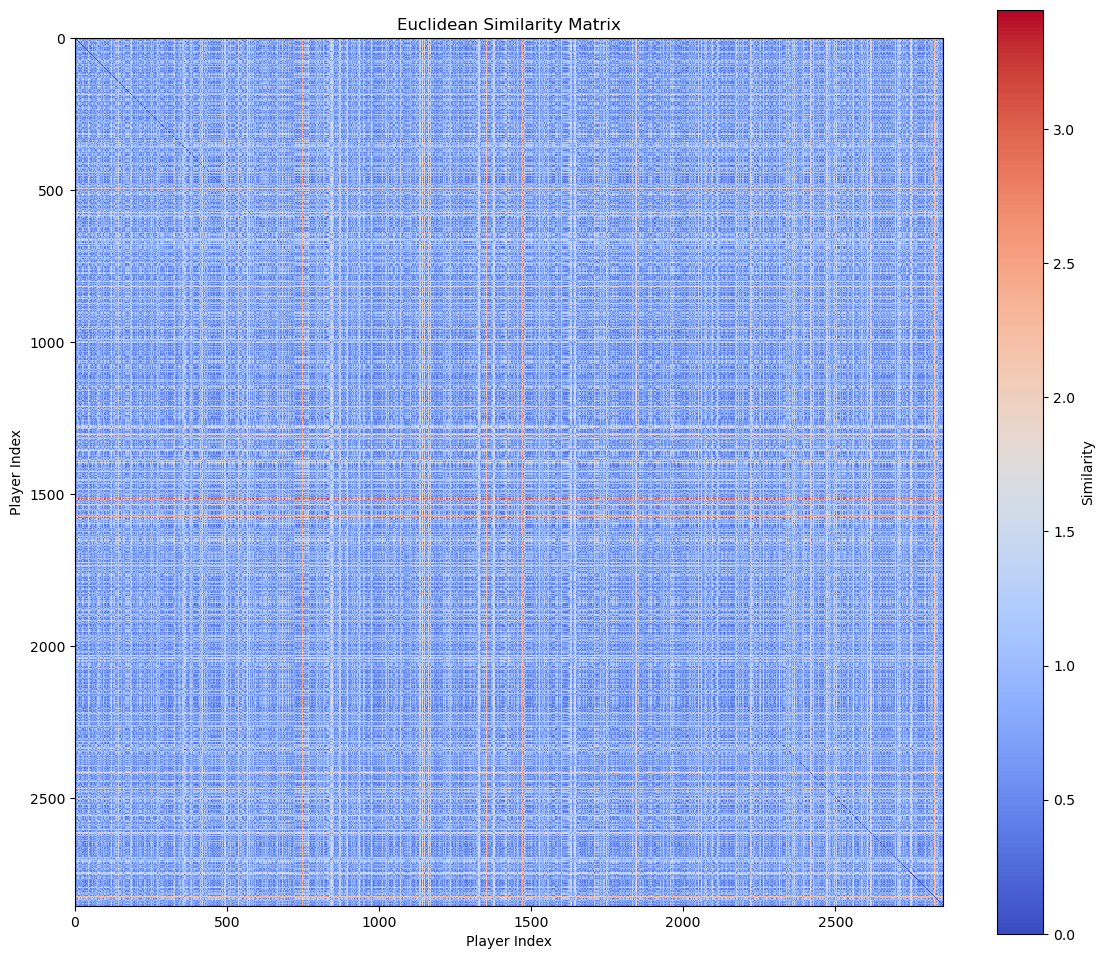

In [17]:
# Plot Euclidean Similarity Matrix
plt.figure(figsize=(14, 12))
plt.imshow(similarity_euclidean, cmap='coolwarm', interpolation='nearest')
plt.colorbar(label='Similarity')
plt.title('Euclidean Similarity Matrix')
plt.xlabel('Player Index')
plt.ylabel('Player Index')
plt.show()

In [ ]:
def get_top_n_similar_players(player_name, df_players_norm, similarity_matrix, n=5, max_market_value=sys.maxsize, threshold=10, same_position=False):

    # Calcola il valore di mercato massimo con soglia
    threshold_value = max_market_value * (threshold / 100)
    max_value_with_threshold = max_market_value + threshold_value

    # Filtra i giocatori in base al valore di mercato
    filtered_players = df_players_norm[df_players_norm['Market Value'] <= max_value_with_threshold]

    # Filtra i giocatori per posizione se il flag è attivo
    if same_position:
        player_position = df_players_norm[df_players_norm['Player'] == player_name]['Position'].values[0]
        filtered_players = filtered_players[filtered_players['Position'] == player_position]

    # Ottieni lo score di similarità del giocatore selezionato
    player_similarities = list(enumerate(similarity_matrix[df_players_norm[df_players_norm['Player'] == player_name].index.values][0]))

    # Ordina i giocatori per similarità
    player_similarities = sorted(player_similarities, key=lambda x: x[1], reverse=False)
    
    # Seleziona i primi n giocatori simili
    top_n_similar_players = [p for p in player_similarities[1:] if df_players_norm.iloc[p[0]]['Player'] in filtered_players['Player'].values][:n]
    
    print(f"Top {n} players similar to {player_name} with market value <= {max_value_with_threshold / 1e6}m:")
    for i, (player_index, similarity_score) in enumerate(top_n_similar_players):
        print(f"{i+1}. {df_players_norm.iloc[player_index]['Player']} - Distance: {similarity_score:.2f}")

    # Preparazione per il grafico a radar
    stats = df_players_norm.columns[1:-1]  # Escludi la colonna 'Player' e l'ultima colonna
    num_stats = len(stats)

    # Coordinate angolari per il radar
    angles = np.linspace(0, 2 * np.pi, num_stats, endpoint=False).tolist()
    angles += angles[:1]  # Chiudere il grafico

    # Inizializza il plot
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'polar': True})
    
    # Aggiungi il giocatore selezionato
    player_index = df_players_norm[df_players_norm['Player'] == player_name].index.values[0]
    values = df_players_norm.iloc[player_index].values[1:-1].tolist()
    values += values[:1]
    ax.plot(angles, values, label=player_name, linewidth=2, linestyle='solid')
    ax.fill(angles, values, alpha=0.25)

    # Aggiungi i giocatori simili
    for similar_index, _ in top_n_similar_players:
        similar_values = df_players_norm.iloc[similar_index].values[1:-1].tolist()
        similar_values += similar_values[:1]
        ax.plot(angles, similar_values, label=df_players_norm.iloc[similar_index]['Player'], linewidth=1, linestyle='dashed')
        ax.fill(angles, similar_values, alpha=0.1)

    average_similarity = np.mean([similarity for _, similarity in top_n_similar_players])
    print(f"Average Distance: {average_similarity:.2f}")

    # Imposta le etichette
    ax.set_yticks([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(stats, fontsize=10)
    ax.set_title(f"Player and Top {n} Similar Players Stats Comparison", size=14)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

    plt.show()

In [19]:
# Ricerca la distanza euclidea tra due giocatori

def get_players_distance(player1, player2, df_players_norm, similarity_matrix):
    player1_index = df_players_norm[df_players_norm['Player'] == player1].index.values[0]
    player2_index = df_players_norm[df_players_norm['Player'] == player2].index.values[0]

    player1_values = df_players_norm.iloc[player1_index].drop(['Player', 'Market Value']).values
    player2_values = df_players_norm.iloc[player2_index].drop(['Player', 'Market Value']).values

    distance = similarity_matrix[player1_index][player2_index]
    print(f"Distance between {player1} and {player2}: {distance:.2f}")

    # Plot grafico radar
    stats = df_players_norm.columns.drop(['Player', 'Market Value'])
    num_stats = len(stats)

    angles = np.linspace(0, 2 * np.pi, num_stats, endpoint=False).tolist()
    angles += angles[:1]  

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'polar': True})
    ax.plot(angles, player1_values.tolist() + player1_values[:1].tolist(), label=player1, linewidth=2, linestyle='solid')
    ax.fill(angles, player1_values.tolist() + player1_values[:1].tolist(), alpha=0.25)
    ax.plot(angles, player2_values.tolist() + player2_values[:1].tolist(), label=player2, linewidth=2, linestyle='dashed')
    ax.fill(angles, player2_values.tolist() + player2_values[:1].tolist(), alpha=0.25)
    ax.set_yticks([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(stats, fontsize=10)
    ax.set_title(f"{player1} and {player2} Stats Comparison", size=14)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    plt.show()

Top 10 players similar to Marcus Thuram with market value <= 10145709240540.254m:
1. André Silva - Distance: 0.27
2. Donyell Malen - Distance: 0.31
3. Dominic Solanke - Distance: 0.31
4. Álvaro Morata - Distance: 0.32
5. Michail Antonio - Distance: 0.33
6. Gabriel Jesus - Distance: 0.34
7. Duván Zapata - Distance: 0.37
8. Edin Džeko - Distance: 0.38
9. Randal Kolo Muani - Distance: 0.38
10. Bryan Mbeumo - Distance: 0.38
Average Distance: 0.34


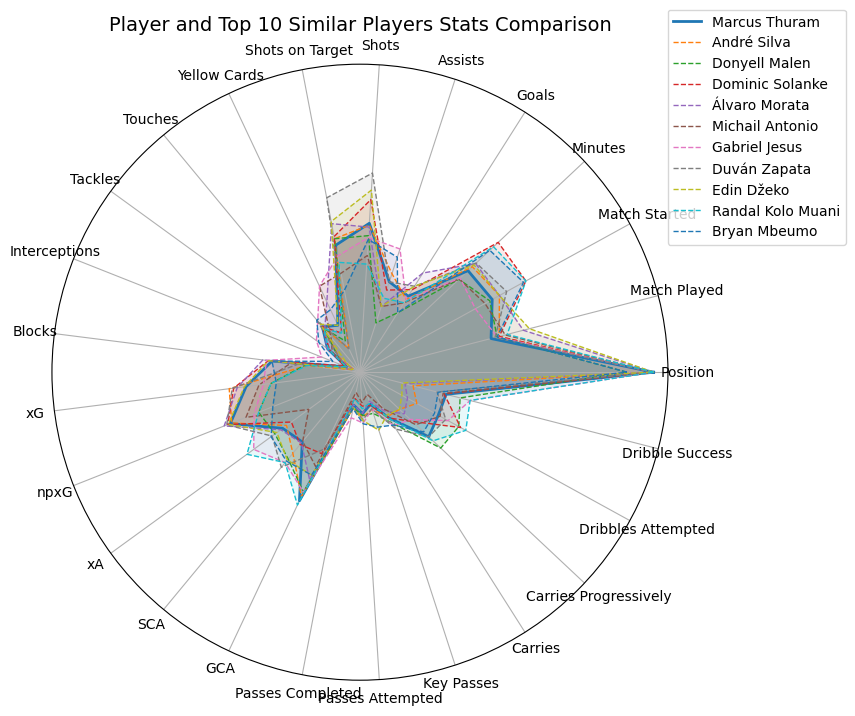

In [20]:
get_top_n_similar_players('Marcus Thuram', df_players_norm, similarity_euclidean, n=10, max_market_value = sys.maxsize ,threshold=10, same_position=False)

Distance between Marcus Thuram and Romelu Lukaku: 0.39


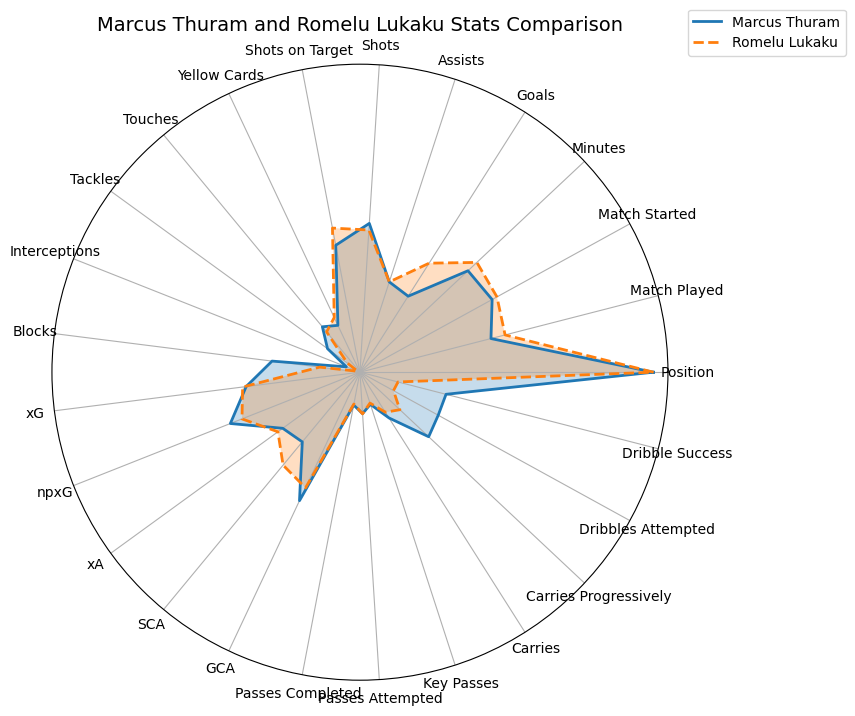

In [23]:
get_players_distance('Marcus Thuram', 'Romelu Lukaku', df_players_norm, similarity_euclidean)

---

# Addendum: Methodology Review and Corrections (post-thesis)

This section was added after the thesis was discussed and graded. A closer review of the
similarity methodology (see the project README for full details) found that:

1. The original pipeline compared **season totals** instead of **per-90-minute rates**,
   so the similarity score was heavily influenced by playing time rather than playing style.
2. `Position` (an arbitrary ordinal code, CB=1 ... FW=12) was aggregated with a **median**
   across matches/seasons, which can produce a nonsensical "position" for players used in
   multiple roles.
3. Players for whom no market value could be scraped from Transfermarkt were **dropped from
   the entire similarity pool**, not just from market-value-filtered searches.

The cells below redo the aggregation using **per-90 rates** and a **mode-based position**
(kept as metadata only, not fed into the distance -- see the note below), and **keep
players with an unresolved market value** in the comparison pool.
No new scraping is performed: only the already-saved per-match CSVs
(`players_stats_YY_YY.csv`) and the already-saved `players_market_value.csv` are used, since
some of the original sources can no longer be scraped as-is.

The original notebook above (and the thesis PDF/DOCX) are left unchanged, since they reflect
the work as it was discussed and graded.

**A note on Position**: an earlier version of this fix one-hot-encoded `Position` into the
distance features, reasoning that an ordinal code shouldn't be averaged with a median. That
turned out to overcorrect the original bug: it made the *minimum* distance to any
player of a *different* position (1.44) higher than the *average* distance between
*same-position* players (0.50) -- i.e. position became a hard partition instead of a soft
signal, exactly the opposite failure mode, and it's what let the original thesis surface
genuine cross-position matches (e.g. Thuram-Dzeko). Position is therefore excluded from the
distance computation entirely below, and kept only as metadata / for the existing
`same_position` filter.


### `fix_pipeline.py` — corrected aggregation, position handling and market-value merge

In [ ]:
# -*- coding: utf-8 -*-
"""
Corrected aggregation / normalization / similarity pipeline.
Fixes (vs. original thesis notebook):
  1. Per-90-minute rates instead of raw season totals (removes playing-time bias).
  2. Position via mode (most frequent role) instead of median of an ordinal code,
     kept as metadata/optional filter only -- NOT fed into the distance metric
     (see note below on why one-hot encoding it was tried and rejected).
  3. Players without a scraped market value are kept in the similarity pool
     (only excluded when a market-value cap is actually requested).

Note on Position: an earlier version of this fix one-hot-encoded Position into
the distance features. That turned out to overcorrect the original bug: it made
the minimum distance to ANY player of a different position (1.44) higher than
the AVERAGE distance between same-position players (0.50), i.e. position became
a hard partition instead of a soft signal, and it's what let the original
(flawed) thesis surface cross-position matches like Thuram-Dzeko. Position is
therefore left out of the distance computation entirely here, and only used
as metadata / through the existing `same_position` filter.

No new scraping is performed: only the already-saved per-match CSVs and the
already-saved market value CSV are used as input.
"""
import pandas as pd
import numpy as np
import re
import sys

RATE_STATS = [
    'Goals', 'Assists', 'Shots', 'Shots on Target', 'Yellow Cards', 'Touches',
    'Tackles', 'Interceptions', 'Blocks', 'xG', 'npxG', 'xA', 'SCA', 'GCA',
    'Passes Completed', 'Passes Attempted', 'Key Passes', 'Carries',
    'Carries Progressively', 'Dribbles Attempted', 'Dribble Success'
]

POSITION_MAP_INV = {
    1: 'CB', 2: 'LB', 3: 'RB', 4: 'WB', 5: 'DM', 6: 'CM', 7: 'LM',
    8: 'RM', 9: 'AM', 10: 'LW', 11: 'RW', 12: 'FW'
}


def load_season(path):
    return pd.read_csv(path, encoding='utf-8')


def per90_season_aggregate(df):
    """Per player, per season: sum raw counts, sum minutes, derive per-90 rates,
    and take the mode of Position (most frequently played role)."""
    grouped_sum = df.groupby('Player')[RATE_STATS + ['Minutes']].sum()
    matches = df.groupby('Player').size().rename('Match Played')
    started = df.groupby('Player')['Start'].sum().rename('Match Started')
    position_mode = df.groupby('Player')['Position'].agg(
        lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan
    ).rename('Position')

    minutes = grouped_sum['Minutes'].replace(0, np.nan)
    per90 = grouped_sum[RATE_STATS].div(minutes, axis=0) * 90

    out = per90.join(matches).join(started).join(position_mode)
    out['Minutes'] = grouped_sum['Minutes']
    out = out.reset_index()
    return out


def combine_seasons(season_dfs):
    """Median of per-90 rates across the seasons a player appears in;
    overall mode of Position across all seasons, weighted by matches played
    per season (so a one-off cameo season doesn't outvote a full season)."""
    all_rows = pd.concat(season_dfs, ignore_index=True)

    rate_median = all_rows.groupby('Player')[RATE_STATS].median()
    totals = all_rows.groupby('Player')[['Minutes', 'Match Played', 'Match Started']].sum()

    pos_rows = []
    for _, r in all_rows.iterrows():
        if pd.notna(r['Position']) and r['Match Played'] > 0:
            pos_rows.extend([(r['Player'], r['Position'])] * int(r['Match Played']))
    pos_df = pd.DataFrame(pos_rows, columns=['Player', 'Position'])
    position_mode = pos_df.groupby('Player')['Position'].agg(lambda s: s.mode().iloc[0]).rename('Position')

    out = rate_median.join(totals).join(position_mode).reset_index()
    out['Position Label'] = out['Position'].map(POSITION_MAP_INV)
    return out


def convert_market_value(value):
    if pd.isna(value):
        return np.nan
    m = re.search(r'\d.*', str(value))
    if not m:
        return np.nan
    v = m.group()
    if 'm' in v:
        return float(v.replace('m', '')) * 1_000_000
    if 'k' in v:
        return float(v.replace('k', '')) * 1_000
    try:
        return float(v)
    except ValueError:
        return np.nan


def main():
    seasons = ['20_21', '21_22', '22_23', '23_24']
    season_aggs = []
    for s in seasons:
        df = load_season(f'players_stats_{s}.csv')
        season_aggs.append(per90_season_aggregate(df))
        print(f'season {s}: {df.shape[0]} match rows, {df["Player"].nunique()} players', file=sys.stderr)

    df_players = combine_seasons(season_aggs)
    print('combined players:', df_players.shape, file=sys.stderr)

    mv = pd.read_csv('players_market_value.csv', encoding='utf-8')
    mv['Market Value'] = mv['Market Value'].apply(convert_market_value)
    df_players = df_players.merge(mv, on='Player', how='left')
    n_missing = df_players['Market Value'].isna().sum()
    print(f'players kept without a market value: {n_missing} / {len(df_players)}', file=sys.stderr)

    from sklearn.preprocessing import MinMaxScaler
    scaler = MinMaxScaler()
    df_norm = df_players.copy()
    df_norm[RATE_STATS] = scaler.fit_transform(df_players[RATE_STATS])

    # Position is NOT part of the distance features (see module docstring) --
    # kept only as metadata for the same_position filter / display.
    from sklearn.metrics.pairwise import euclidean_distances
    similarity = euclidean_distances(df_norm[RATE_STATS].values)

    df_norm.to_csv('players_norm_fixed.csv', index=False, encoding='utf-8')
    np.save('similarity_euclidean_fixed.npy', similarity)
    print('saved players_norm_fixed.csv, similarity_euclidean_fixed.npy', file=sys.stderr)
    print('distance feature shape:', df_norm[RATE_STATS].shape, file=sys.stderr)


if __name__ == '__main__':
    main()


### `case_study_fixed.py` — rerun the Thuram / Pavard case study on the corrected data

Top 10 similar to Marcus Thuram (per-90 stats, corrected):
  Michail Antonio (FW) - distance 0.183
  Nicolas Jackson (FW) - distance 0.190
  Breel Embolo (FW) - distance 0.192
  Hugo Ekitike (FW) - distance 0.196
  Anthony Martial (FW) - distance 0.213
  Duván Zapata (FW) - distance 0.218
  Ihlas Bebou (FW) - distance 0.228
  Matheus Cunha (FW) - distance 0.230
  Timo Werner (FW) - distance 0.232
  André Silva (FW) - distance 0.244

Distance Marcus Thuram <-> Romelu Lukaku: 0.361

Top 10 similar to Benjamin Pavard (per-90 stats, corrected):
  Niklas Süle (CB) - distance 0.165
  Hiroki Ito (CB) - distance 0.208
  Thiago Mendes (CM) - distance 0.209
  Eric García (CB) - distance 0.218
  Kim Min-jae (CB) - distance 0.220
  Edmond Tapsoba (CB) - distance 0.224
  Facundo Medina (CB) - distance 0.227
  Daley Blind (CB) - distance 0.229
  Joe Gomez (RB) - distance 0.230
  Marcel Halstenberg (CB) - distance 0.230

Top 10 similar to João Cancelo (per-90 stats, corrected):
  Renato Sanches (CM) 

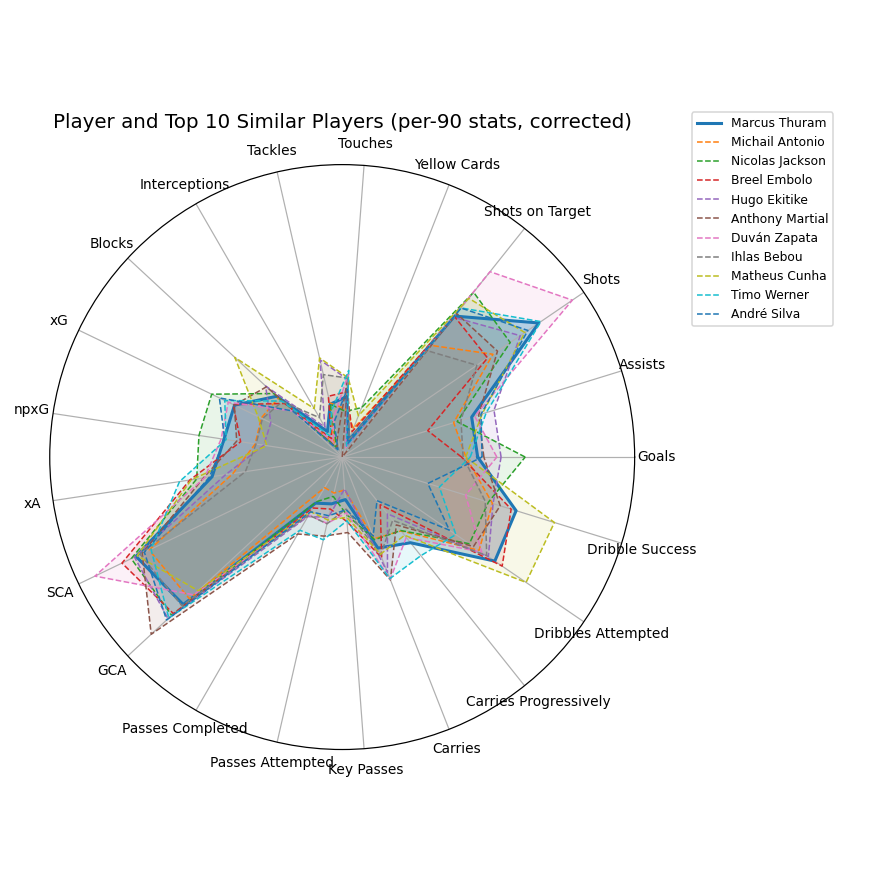

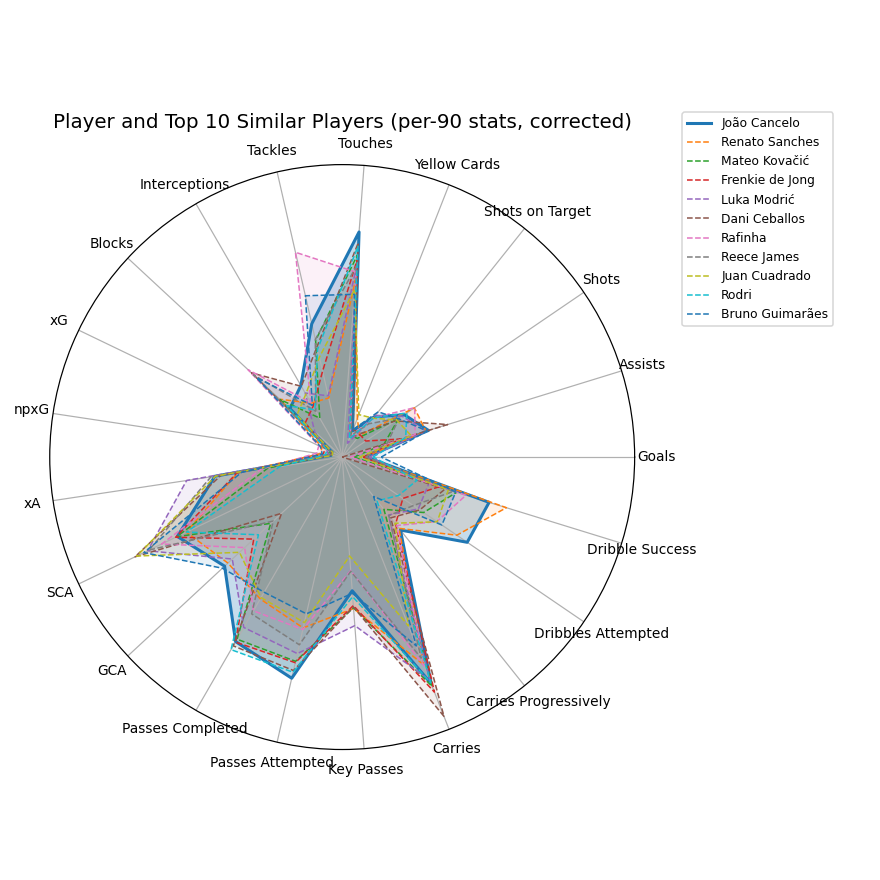

In [ ]:
# -*- coding: utf-8 -*-
"""
Reproduces the Thuram / Pavard case study using the corrected similarity
pipeline (see fix_pipeline.py). Run fix_pipeline.py first to generate
players_norm_fixed.csv and similarity_euclidean_fixed.npy.
"""
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import sys

RATE_STATS = [
    'Goals', 'Assists', 'Shots', 'Shots on Target', 'Yellow Cards', 'Touches',
    'Tackles', 'Interceptions', 'Blocks', 'xG', 'npxG', 'xA', 'SCA', 'GCA',
    'Passes Completed', 'Passes Attempted', 'Key Passes', 'Carries',
    'Carries Progressively', 'Dribbles Attempted', 'Dribble Success'
]

df = pd.read_csv('players_norm_fixed.csv', encoding='utf-8')
sim = np.load('similarity_euclidean_fixed.npy')


def top_n_similar(player_name, n=10, max_market_value=None):
    idx = df.index[df['Player'] == player_name]
    if len(idx) == 0:
        print(f'{player_name} not found', file=sys.stderr)
        return []
    idx = idx[0]
    scores = sorted(list(enumerate(sim[idx])), key=lambda x: x[1])
    results = []
    for i, score in scores[1:]:
        if max_market_value is not None:
            mv = df.iloc[i]['Market Value']
            if pd.notna(mv) and mv > max_market_value:
                continue
        results.append((i, df.iloc[i]['Player'], df.iloc[i]['Position Label'], score))
        if len(results) == n:
            break
    print(f'Top {n} similar to {player_name} (per-90 stats, corrected):')
    for _, name, pos, score in results:
        print(f'  {name} ({pos}) - distance {score:.3f}')
    return results


def players_distance(p1, p2):
    i1 = df.index[df['Player'] == p1][0]
    i2 = df.index[df['Player'] == p2][0]
    print(f'Distance {p1} <-> {p2}: {sim[i1][i2]:.3f}')


def plot_radar(player_name, results, out_path):
    idx = df.index[df['Player'] == player_name][0]
    angles = np.linspace(0, 2 * np.pi, len(RATE_STATS), endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'polar': True})
    values = df.iloc[idx][RATE_STATS].values.tolist()
    values += values[:1]
    ax.plot(angles, values, label=player_name, linewidth=2, linestyle='solid')
    ax.fill(angles, values, alpha=0.25)

    for i, name, _, _ in results:
        v = df.iloc[i][RATE_STATS].values.tolist()
        v += v[:1]
        ax.plot(angles, v, label=name, linewidth=1, linestyle='dashed')
        ax.fill(angles, v, alpha=0.1)

    ax.set_yticks([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(RATE_STATS, fontsize=9)
    ax.set_title(f"Player and Top {len(results)} Similar Players (per-90 stats, corrected)", size=13)
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=8)
    plt.tight_layout()
    plt.savefig(out_path, dpi=110)
    print(f'saved {out_path}')


if __name__ == '__main__':
    results = top_n_similar('Marcus Thuram', n=10)
    print()
    players_distance('Marcus Thuram', 'Romelu Lukaku')
    print()
    top_n_similar('Benjamin Pavard', n=10)
    print()
    # Stress test: Cancelo is famous for playing all over the pitch (full-back,
    # wing-back, central midfield depending on the system) -- a good check that
    # Position is genuinely not driving the distance.
    cancelo_results = top_n_similar('João Cancelo', n=10)
    print()
    plot_radar('Marcus Thuram', results, 'assets/similar_players_corrected.png')
    plot_radar('João Cancelo', cancelo_results, 'assets/cancelo_similarity.png')


## Result: do the thesis's conclusions still hold?

Yes. With the corrected per-90 methodology:
- The players most similar to **Marcus Thuram** are still almost exclusively center-forwards
  (Michail Antonio, Nicolas Jackson, Breel Embolo, Hugo Ekitike, Anthony Martial, ...).
- The players most similar to **Benjamin Pavard** are mostly center-backs (Niklas Süle,
  Hiroki Ito, Eric García, Kim Min-jae, ...), with a couple of cross-position matches
  (Thiago Mendes, Joe Gomez) surfacing on stats alone -- the kind of nuance the original
  thesis's narrative (e.g. Thuram-Dzeko) relied on, and that a hard position filter would
  have hidden.

This is consistent with the original thesis's narrative around Inter Milan's transfer
strategy, even though 247 additional players (previously dropped for lacking a scraped
market value) are now included in the comparison pool.

**Stress test -- João Cancelo.** A good test for whether position is genuinely absent from
the distance is a player famous for playing all over the pitch: Cancelo (nominally a
left-back) comes back with a deliberately position-diverse list -- central midfielders
(Mateo Kovačić, Renato Sanches, Bruno Guimarães, Rodri), wing-backs (Reece James, Juan
Cuadrado), and even attacking midfielders (Luka Modrić, Frenkie de Jong) alongside
conventional full-backs -- reflecting his real-world reputation as an "inverted full-back"
who often plays like a central midfielder. A hard position filter (like the rejected
one-hot attempt) would have missed this entirely.
